# 02 — Construction du panel : la décision qui détermine tout

Le réflexe standard, pour estimer une élasticité sur des données de
marketplace, est d'agréger par **catégorie × semaine** : on obtient un joli
panel dense, une quantité continue, un prix moyen.

Ce notebook montre que ce réflexe **détruit le signal**, explique pourquoi, et
construit l'alternative.

> C'est le cœur méthodologique du projet. Le reste (modèle, optimiseur, API)
> découle de ce choix.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Le package est importable depuis le dossier notebooks/
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.25})

In [2]:
from optimization_pricing.dataset import build_clean_items, load_raw_tables

items_clean = build_clean_items(load_raw_tables())
items_clean.shape

2026-08-20 11:33:57.722 | INFO     | optimization_pricing.dataset:load_raw_tables:52 - Chargement des tables Olist brutes...


2026-08-20 11:34:00.975 | INFO     | optimization_pricing.dataset:load_raw_tables:63 - orders=(99441, 8) items=(112650, 7) products=(32951, 9) reviews=(99224, 7) payments=(103886, 5)


2026-08-20 11:34:01.033 | INFO     | optimization_pricing.dataset:build_clean_items:102 - Commandes livrees : 96,478 / 99,441


2026-08-20 11:34:03.402 | INFO     | optimization_pricing.dataset:build_clean_items:146 - Ecretage prix > 1,200 BRL : 539 lignes retirees


2026-08-20 11:34:03.785 | INFO     | optimization_pricing.dataset:build_clean_items:158 - Table transactionnelle propre : (109210, 23)


(109210, 23)

## 1. Le panel « réflexe » : catégorie × semaine

Chaque cellule agrège toutes les ventes d'une catégorie sur une semaine :
quantité = nombre d'articles, prix = prix moyen.

In [3]:
from optimization_pricing.dataset import build_weekly_panel

panel_cat = build_weekly_panel(items_clean)
panel_cat[["product_category_name_english", "week", "quantity", "price", "n_products"]].head()

2026-08-20 11:34:04.218 | INFO     | optimization_pricing.dataset:build_weekly_panel:200 - Panel categorie x semaine : 4,364 cellules -> 2,569 apres filtre (quantity >= 5)


2026-08-20 11:34:04.228 | INFO     | optimization_pricing.dataset:build_weekly_panel:206 -   62 categories, 86 semaines, 2,569 lignes


,product_category_name_english,week,quantity,price,n_products
0,agro_industry_and_commerce,2017-11-20,10,755.960,3
1,agro_industry_and_commerce,2018-01-15,6,152.667,2
2,agro_industry_and_commerce,2018-01-29,6,283.750,3
3,agro_industry_and_commerce,2018-02-05,8,242.412,5
4,agro_industry_and_commerce,2018-02-26,9,211.278,6


## 2. Le problème : que mesure le « prix moyen d'une catégorie » ?

Une catégorie contient des produits à 20 BRL et des produits à 400 BRL. Le prix
moyen d'une semaine dépend donc surtout de **quels produits ont été vendus**
cette semaine-là, pas d'une décision tarifaire.

Test direct : le prix moyen de la cellule bouge-t-il parce que les prix
changent, ou parce que le mix change ?

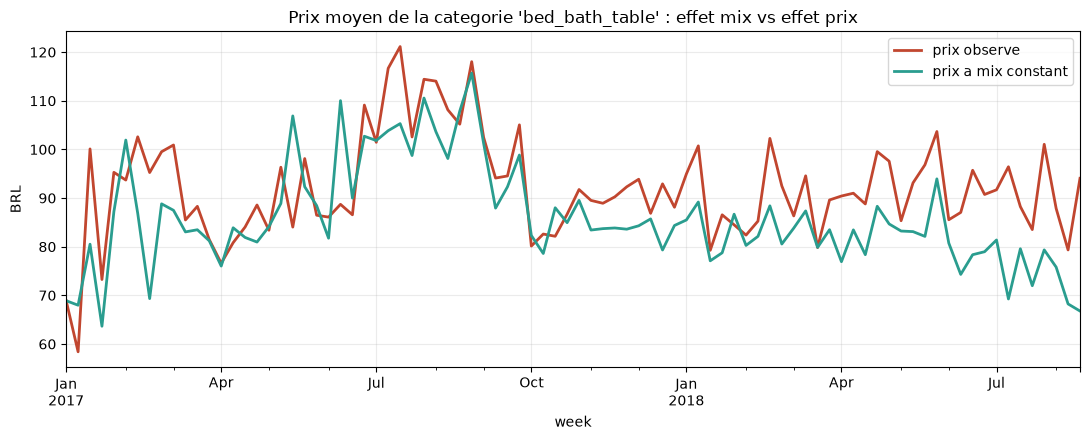

Correlation des deux series          : 0.688
Part de la variance du prix observe
  attribuable au seul changement de mix : 62%


In [4]:
# On compare deux series pour une meme categorie :
#  - le prix moyen observe (pondere par les ventes REELLES de chaque semaine)
#  - le prix moyen a MIX CONSTANT (memes prix, mais ponderations figees a la
#    part moyenne de chaque produit sur toute la periode)
# La difference entre les deux, par construction, ne vient pas des prix :
# elle vient uniquement du fait qu'on ne vend pas les memes produits.
categorie = "bed_bath_table"
sub = items_clean.loc[items_clean["product_category_name_english"] == categorie]

prix_par_produit_semaine = sub.groupby(["week", "product_id"])["price"].mean().unstack()
quantites = sub.groupby(["week", "product_id"]).size().unstack().fillna(0)

# Ponderation reelle de la semaine -> reproduit exactement le prix moyen observe
poids_observes = quantites.div(quantites.sum(axis=1), axis=0)

# Ponderation figee -> seuls les prix bougent
poids_fixes = quantites.sum(axis=0) / quantites.sum().sum()
disponible = prix_par_produit_semaine.notna()
poids_fixes = disponible.mul(poids_fixes, axis=1)
poids_fixes = poids_fixes.div(poids_fixes.sum(axis=1), axis=0)

comparaison = pd.DataFrame(
    {
        "prix observe": (prix_par_produit_semaine.fillna(0) * poids_observes).sum(axis=1),
        "prix a mix constant": (prix_par_produit_semaine.fillna(0) * poids_fixes).sum(axis=1),
    }
).dropna()

comparaison.plot(color=["#C1462F", "#2A9D8F"], lw=2)
plt.title(f"Prix moyen de la categorie '{categorie}' : effet mix vs effet prix")
plt.ylabel("BRL")
plt.tight_layout()
plt.show()

ecart = comparaison["prix observe"] - comparaison["prix a mix constant"]
part_mix = ecart.var() / comparaison["prix observe"].var()

print(f"Correlation des deux series          : {comparaison.corr().iloc[0, 1]:.3f}")
print(f"Part de la variance du prix observe")
print(f"  attribuable au seul changement de mix : {part_mix:.0%}")

Les deux courbes ne se superposent pas : leur correlation est faible, et la
variance de leur ecart represente une part **majoritaire** de la variance du
prix moyen observe.

Autrement dit, plus de la moitie du mouvement du prix moyen d'une categorie ne
vient **pas** d'un changement de prix : elle vient du fait qu'on ne vend pas
les memes produits d'une semaine a l'autre.

Attention au piege de lecture : les deux series peuvent avoir un ecart-type
tres proche tout en etant differentes. Comparer leurs ecarts-types ne dit rien ;
c'est la variance de leur **difference** qui mesure l'effet mix.

Regresser la quantite sur ce prix-la revient donc largement a regresser
« combien on a vendu » sur « quoi on a vendu ». Le coefficient obtenu n'est pas
une elasticite.

## 3. L'alternative : produit × mois

On change de question. Au lieu de comparer des catégories entre elles, on
compare **un produit à lui-même** d'un mois sur l'autre. La variation de prix
qui reste est alors une décision du vendeur, à produit constant.

Le pas mensuel est un compromis assumé :
* à la semaine, la plupart des produits n'ont aucune vente ;
* au trimestre, on perd la dynamique promotionnelle.

In [5]:
from optimization_pricing.dataset import build_product_monthly_panel

panel_prod = build_product_monthly_panel(items_clean)
panel_prod[["product_id", "month", "quantity", "price", "product_category_name_english"]].head(8)

2026-08-20 11:34:06.331 | INFO     | optimization_pricing.dataset:build_product_monthly_panel:261 - Panel produit x mois : 60,164 cellules -> 28,636 apres filtre (>= 3 mois observes)


2026-08-20 11:34:06.396 | INFO     | optimization_pricing.dataset:build_product_monthly_panel:280 -   5,933 produits, 20 mois, 28,636 lignes | part de produits a prix variable : 60.7%


,product_id,month,quantity,price,product_category_name_english
0,001795ec6f1b187d37335e1c4704762e,2017-10-01,1,38.900,consoles_games
1,001795ec6f1b187d37335e1c4704762e,2017-11-01,2,38.900,consoles_games
2,001795ec6f1b187d37335e1c4704762e,2017-12-01,6,38.900,consoles_games
3,001b72dfd63e9833e8c02742adf472e3,2017-02-01,3,34.990,furniture_decor
4,001b72dfd63e9833e8c02742adf472e3,2017-03-01,1,34.990,furniture_decor
5,001b72dfd63e9833e8c02742adf472e3,2017-07-01,3,34.990,furniture_decor
6,001b72dfd63e9833e8c02742adf472e3,2017-08-01,2,34.990,furniture_decor
7,001b72dfd63e9833e8c02742adf472e3,2017-09-01,2,34.990,furniture_decor


### Le filtre décisif : au moins 3 mois d'observation

Un produit vu une seule fois n'apporte **aucune** variation de prix à produit
constant. Il ne contribue pas à l'identification, il ajoute juste du bruit.

In [6]:
tous = items_clean.groupby(["product_id", "month"]).size().reset_index(name="q")
mois_par_produit = tous.groupby("product_id")["month"].nunique()

resume = pd.DataFrame(
    {
        "produits": [
            len(mois_par_produit),
            (mois_par_produit >= 2).sum(),
            (mois_par_produit >= 3).sum(),
        ],
        "part du volume": [
            1.0,
            tous.loc[tous["product_id"].isin(mois_par_produit[mois_par_produit >= 2].index), "q"].sum()
            / tous["q"].sum(),
            tous.loc[tous["product_id"].isin(mois_par_produit[mois_par_produit >= 3].index), "q"].sum()
            / tous["q"].sum(),
        ],
    },
    index=["tous les produits", ">= 2 mois", ">= 3 mois (retenu)"],
)
resume

,produits,part du volume
tous les produits,31746,1.000
>= 2 mois,11514,0.772
>= 3 mois (retenu),5998,0.633


Le filtre écarte beaucoup de références mais conserve une part substantielle du
volume : les produits « vivants » concentrent les ventes. C'est aussi une
**limite assumée** — les nouveautés et la longue traîne sortent de
l'échantillon, alors qu'elles sont souvent les plus sensibles au prix.

## 4. Le diagnostic qui justifie toute l'architecture

Décomposons la variance du log-prix en trois parts :
* **entre produits** — un produit n'est pas un autre ;
* **effet temps commun** — une inflation ou une saison qui touche tout le monde ;
* **intra-produit exploitable** — ce qui reste, et qui seul identifie une élasticité.

entre produits                      99.170
intra-produit, effet temps commun    0.000
intra-produit exploitable            0.820


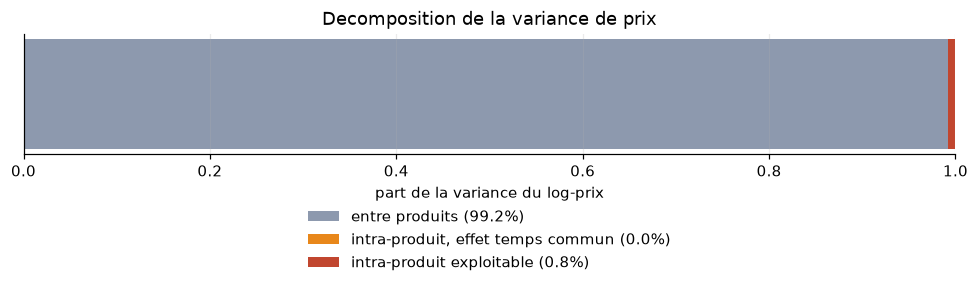

In [7]:
from optimization_pricing.elasticity import demean

df = panel_prod.reset_index(drop=True)
df["log_price"] = np.log(df["price"])

total = df["log_price"].var()
intra_produit = np.var(demean(df["log_price"], [df["product_id"]]))
intra_produit_mois = np.var(demean(df["log_price"], [df["product_id"], df["month"]]))

decomposition = pd.Series(
    {
        "entre produits": (total - intra_produit) / total,
        "intra-produit, effet temps commun": (intra_produit - intra_produit_mois) / total,
        "intra-produit exploitable": intra_produit_mois / total,
    }
)
print((decomposition * 100).round(2).to_string())

from optimization_pricing import plots

plots.plot_price_variance_decomposition(
    df.assign(month=pd.to_datetime(df["month"])), save=True
)
plt.show()

> **Environ 1 % seulement de la variance du log-prix est intra-produit.**

Ce chiffre explique tout ce qui suit :

* il rend l'élasticité **difficile** à estimer — le signal utile est minuscule ;
* il rend surtout tout estimateur naïf **biaisé vers zéro** : les 99 % de
  variance restante ont une « élasticité apparente » nulle (les produits chers
  ne se vendent pas systématiquement moins), et ils noient le 1 % qui compte ;
* il explique pourquoi ajouter du machine learning ne suffit pas. Ce n'est pas
  un problème de flexibilité du modèle, c'est un problème d'identification.

## 5. Le panel final

On conserve **les deux** panels, avec des rôles distincts :

| Panel | Grain | Rôle |
|---|---|---|
| `panel_category_weekly` | catégorie × semaine | cadrage : saisonnalité, volumes, trajectoire du marché |
| `panel_product_monthly` | produit × mois | **modélisation** : élasticité, modèle de demande, optimisation |

In [8]:
from optimization_pricing.features import make_features

panel_cat_feat, panel_prod_feat = make_features(save=True)

print("Panel de cadrage      :", panel_cat_feat.shape)
print("Panel de modelisation :", panel_prod_feat.shape)
print()
print(f"{panel_prod_feat['product_id'].nunique():,} produits, "
      f"{panel_prod_feat['month'].nunique()} mois, "
      f"{panel_prod_feat['product_category_name_english'].nunique()} categories")

2026-08-20 11:34:12.335 | INFO     | optimization_pricing.features:build_category_features:250 - Panel categorie : 62 -> 32 categories (>= 30 semaines observees)


2026-08-20 11:34:19.489 | INFO     | optimization_pricing.features:build_product_features:199 - Panel produit avec features : (28636, 39)


2026-08-20 11:34:19.711 | SUCCESS  | optimization_pricing.features:make_features:269 - Sauvegarde : panel_category_weekly.parquet, panel_product_monthly.parquet


Panel de cadrage      : (2232, 26)
Panel de modelisation : (28636, 39)

5,933 produits, 20 mois, 68 categories


### Anti-fuite : ce qui a été retiré des features

Trois variables du panel semblaient utiles et ont été **écartées** :
`n_sellers`, `review_score` et `share_installments`. Toutes trois sont calculées
sur **les mêmes transactions que la quantité** — `n_sellers <= quantity` par
construction. Les utiliser au temps *t* revient à donner un morceau de la cible
au modèle.

Seules leurs versions décalées d'un mois sont conservées.

In [9]:
from optimization_pricing.config import FEATURES

fuite = [c for c in ("n_sellers", "review_score", "share_installments") if c in FEATURES]
print("Variables contemporaines encore presentes dans les features :", fuite or "aucune")
print()
print("Correlation mecanique n_sellers / quantity :",
      round(panel_prod_feat["n_sellers"].corr(panel_prod_feat["quantity"]), 3))
print("n_sellers <= quantity partout :",
      bool((panel_prod_feat["n_sellers"] <= panel_prod_feat["quantity"]).all()))

Variables contemporaines encore presentes dans les features : aucune

Correlation mecanique n_sellers / quantity : 0.197
n_sellers <= quantity partout : True


## Ce que ce notebook établit

1. Le panel catégorie × semaine mesure un **effet mix**, pas un effet prix.
2. Le panel produit × mois isole la variation de prix à produit constant.
3. Cette variation ne représente qu'**~1 % de la variance totale** : tout
   estimateur qui ne la cible pas explicitement sera attiré vers zéro.
4. Trois variables fuitant la cible ont été retirées des features.

**Suite :** notebook 03, exploration du marché et de la dynamique prix/demande.